# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
import imblearn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim != 2 or X.shape[0] != y.size:
            raise ValueError('Некорректные размеры X и y')
        if not np.isin(y, [0, 1]).all():
            raise ValueError('Поддерживаются только метки 0 и 1')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError('gd_type должен быть full или stochastic')
        if self.batch_size < 1 or self.max_iter < 1 or self.eta <= 0:
            raise ValueError('Параметры обучения должны быть положительными')
        X_aug = np.column_stack((np.ones(X.shape[0]), X))
        self.w = np.zeros(X_aug.shape[1]) if self.w0 is None else np.array(self.w0, dtype=float, copy=True)
        if self.w.shape != (X_aug.shape[1],):
            raise ValueError('Неверная размерность начального вектора w0')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.loss_history = []
        self.stop_reason_ = 'max_iter'
        rng = np.random.default_rng(self.random_state)
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X_aug, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X_aug, y)
            else:
                indices = rng.choice(X_aug.shape[0], size=min(self.batch_size, X_aug.shape[0]), replace=False)
                gradient = self.calc_gradient(X_aug[indices], y[indices])
            w_next = self.w - self.eta * gradient
            delta = np.linalg.norm(w_next - self.w)
            self.w = w_next
            if delta < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.n_iter_ = len(self.loss_history)
        return self

    def sigmoid(self, z):
        return expit(z)

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise RuntimeError('Модель ещё не обучена')
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError('Неверное число признаков')
        X_aug = np.column_stack((np.ones(X.shape[0]), X))
        p = self.sigmoid(X_aug @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        if not 0 <= threshold <= 1:
            raise ValueError('Порог должен лежать в диапазоне [0, 1]')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        return X.T @ (self.sigmoid(X @ self.w) - y) / X.shape[0]

    def calc_loss(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        z = X @ self.w
        return float(np.mean(np.logaddexp(0.0, z) - y * z))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 3.27e-11


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,Метод,Итерации,Остановка,Итоговый log-loss
0,Полный GD,1000,max_iter,0.512435
1,Стохастический GD,1000,max_iter,0.512909


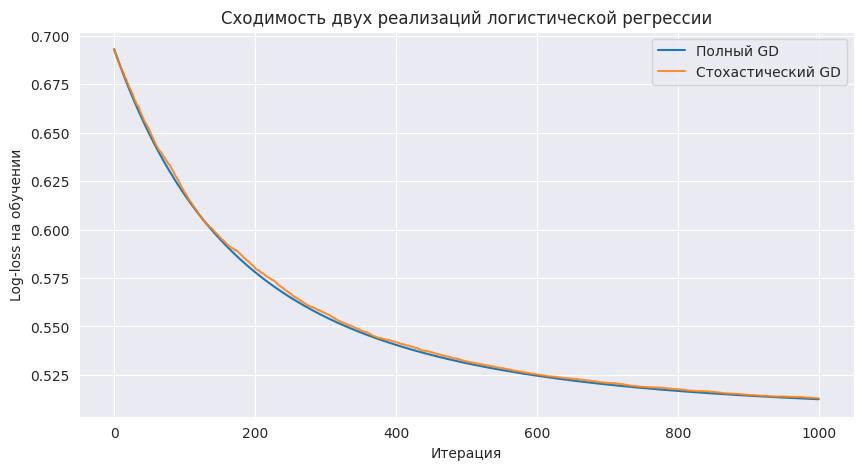

In [6]:
model_gd = LogReg(gd_type='full').fit(X_train, y_train)
model_sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

convergence = pd.DataFrame([
    {'Метод': 'Полный GD', 'Итерации': model_gd.n_iter_, 'Остановка': model_gd.stop_reason_, 'Итоговый log-loss': model_gd.calc_loss(np.column_stack((np.ones(len(X_train)), X_train)), y_train)},
    {'Метод': 'Стохастический GD', 'Итерации': model_sgd.n_iter_, 'Остановка': model_sgd.stop_reason_, 'Итоговый log-loss': model_sgd.calc_loss(np.column_stack((np.ones(len(X_train)), X_train)), y_train)}
])
display(convergence)
plt.figure(figsize=(10, 5))
plt.plot(model_gd.loss_history, label='Полный GD')
plt.plot(model_sgd.loss_history, label='Стохастический GD', alpha=0.85)
plt.xlabel('Итерация')
plt.ylabel('Log-loss на обучении')
plt.title('Сходимость двух реализаций логистической регрессии')
plt.legend()
plt.show()

**Мои выводы.** Обе модели сделали по **1000 итераций** и остановились по `max_iter`, а не по `tolerance`. Полный GD достиг log-loss **0.512435**, SGD — **0.512909**. Полный GD просматривает все **14 000** обучающих объектов на каждой итерации, а стохастический — случайные **32**. Поэтому полный спуск даёт более гладкую траекторию потерь, а SGD — колебания из-за шума мини-батчей. При постоянном шаге изменение весов у SGD может не стремиться к нулю даже вблизи минимума, так что выполнить критерий `tolerance` труднее.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

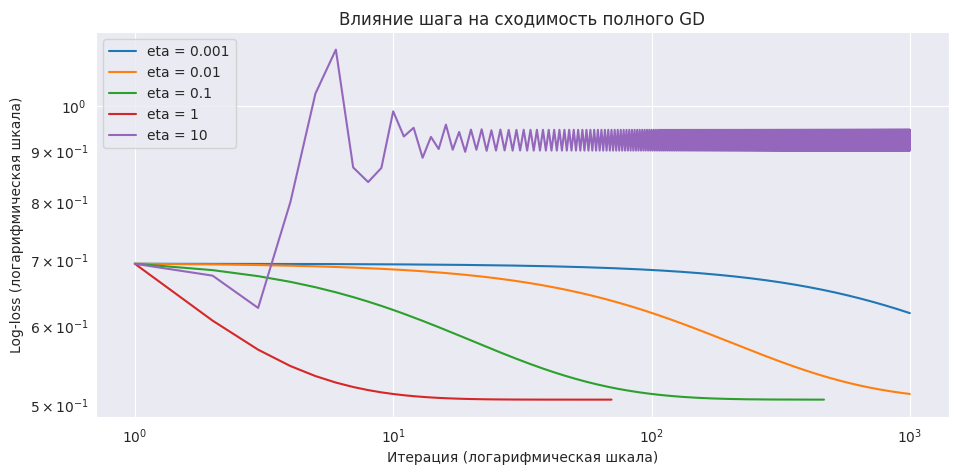

,eta,Итерации,Остановка,Финальный log-loss
0,0.001,1000,max_iter,0.618087
1,0.010,1000,max_iter,0.512435
2,0.100,465,tolerance,0.505762
3,1.000,70,tolerance,0.505757
4,10.000,1000,max_iter,0.901345


In [7]:
step_sizes = [1e-3, 1e-2, 1e-1, 1, 10]
step_rows = []
plt.figure(figsize=(11, 5))
for eta in step_sizes:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    final_loss = model.calc_loss(np.column_stack((np.ones(len(X_train)), X_train)), y_train)
    step_rows.append({'eta': eta, 'Итерации': model.n_iter_, 'Остановка': model.stop_reason_, 'Финальный log-loss': final_loss})
    plt.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=f'eta = {eta:g}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Итерация (логарифмическая шкала)')
plt.ylabel('Log-loss (логарифмическая шкала)')
plt.title('Влияние шага на сходимость полного GD')
plt.legend()
plt.show()
step_results = pd.DataFrame(step_rows)
display(step_results)

**Мои выводы.** При `eta=0.001` алгоритм за 1000 шагов достиг лишь log-loss **0.618087**; при `0.01` — **0.512435**. Шаги `0.1` и `1` сходятся по `tolerance` за **465** и **70** итераций соответственно (потери около **0.50576**). При `eta=10` спуск ведёт себя плохо: за 1000 итераций получен log-loss **0.901345**, то есть даже хуже, чем при умеренных шагах. Следовательно, увеличение шага сначала ускоряет оптимизацию, но после определённой границы приводит к колебаниям и нарушению сходимости.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sklearn_default = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
sklearn_no_penalty = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-10, random_state=RANDOM_STATE).fit(X_train, y_train)
gd_converged = LogReg(gd_type='full', eta=1, max_iter=8000, tolerance=1e-9).fit(X_train, y_train)

models_part1 = {
    'Свой GD (по умолчанию)': model_gd,
    'Свой SGD (по умолчанию)': model_sgd,
    'sklearn (L2 по умолчанию)': sklearn_default,
    'Свой GD (до сходимости)': gd_converged,
    'sklearn (без штрафа)': sklearn_no_penalty
}
part1_scores = []
for name, model in models_part1.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    part1_scores.append({'Модель': name, 'Accuracy': metrics.accuracy_score(y_test, pred), 'ROC-AUC': metrics.roc_auc_score(y_test, proba)})
display(pd.DataFrame(part1_scores).round(5))
weights_gd = pd.Series(model_gd.w, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
weights_sk = pd.Series(np.r_[sklearn_default.intercept_, sklearn_default.coef_.ravel()], index=weights_gd.index)
weights_gd_converged = pd.Series(gd_converged.w, index=weights_gd.index)
weights_sk_nopenalty = pd.Series(np.r_[sklearn_no_penalty.intercept_, sklearn_no_penalty.coef_.ravel()], index=weights_gd.index)
display(pd.DataFrame({'Свой GD': weights_gd, 'sklearn L2': weights_sk, 'Свой GD (сошёлся)': weights_gd_converged, 'sklearn без L2': weights_sk_nopenalty}).round(5))
print('Максимальная разница весов: свой GD (сошёлся) и sklearn без штрафа:', np.max(np.abs(weights_gd_converged - weights_sk_nopenalty)))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,Модель,Accuracy,ROC-AUC
0,Свой GD (по умолчанию),0.7820,0.83879
1,Свой SGD (по умолчанию),0.7825,0.83811
2,sklearn (L2 по умолчанию),0.7765,0.83868
3,Свой GD (до сходимости),0.7765,0.83867
4,sklearn (без штрафа),0.7765,0.83867


,Свой GD,sklearn L2,Свой GD (сошёлся),sklearn без L2
intercept,-0.00211,-0.02188,-0.02216,-0.02216
x0,0.00608,0.00274,0.00276,0.00276
x1,0.00696,0.00904,0.00896,0.00896
x2,-0.54717,-0.72269,-0.72325,-0.72325
x3,-0.14454,-0.26233,-0.26278,-0.26278
x4,0.01249,0.01659,0.01654,0.01654
x5,-0.00632,-0.01149,-0.01155,-0.01155
x6,0.00081,0.00559,0.00558,0.00558
x7,0.03908,0.05719,0.05724,0.05724
x8,-0.00242,-0.00124,-0.00120,-0.00120


Максимальная разница весов: свой GD (сошёлся) и sklearn без штрафа: 8.808671701776571e-09


**Мои выводы.** Accuracy и ROC-AUC моделей близки, но веса моего GD с параметрами по умолчанию и `sklearn` не совпадают: первый делает слишком маленькие шаги и не успевает сойтись за 1000 итераций. Кроме того, `LogisticRegression` по умолчанию использует **L2-регуляризацию**, а мой `LogReg` минимизирует log-loss без штрафа. Для той же задачи в `sklearn` нужно отключить регуляризацию (`C=np.inf` в используемой версии) и обеспечить сходимость. После этого максимальная разница между моим сошедшимся GD и коэффициентами `sklearn` без регуляризации составляет примерно **8.8·10⁻⁹**. Похожее значение ROC-AUC само по себе не гарантирует совпадения коэффициентов.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df_raw = pd.read_csv('wine_quality.csv')
print('Исходный размер:', df_raw.shape)
display(df_raw.head())

Исходный размер: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
df = df_raw.drop_duplicates().reset_index(drop=True)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print('После устранения точных дубликатов:', df.shape)
print('Обучение:', X_train.shape, 'Тест:', X_test.shape)

После устранения точных дубликатов: (5320, 13)
Обучение: (3724, 12) Тест: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
data_quality = pd.DataFrame({
    'Показатель': ['Пропуски в исходном датасете', 'Полные дубликаты', 'Наблюдения до очистки', 'Наблюдения после очистки', 'Доля target=1 на обучении', 'Доля target=1 на тесте'],
    'Значение': [int(df_raw.isna().sum().sum()), int(df_raw.duplicated().sum()), len(df_raw), len(df), y_train.mean(), y_test.mean()]
})
display(data_quality)
constant_predictions = np.zeros(len(y_test), dtype=int)
constant_accuracy = metrics.accuracy_score(y_test, constant_predictions)
base_pipeline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE, max_iter=4000))
base_pipeline.fit(X_train, y_train)
base_accuracy = metrics.accuracy_score(y_test, base_pipeline.predict(X_test))
print(f'Accuracy константной модели: {constant_accuracy:.5f}')
print(f'Accuracy логистической регрессии: {base_accuracy:.5f}')

,Показатель,Значение
0,Пропуски в исходном датасете,0.000000
1,Полные дубликаты,1177.000000
2,Наблюдения до очистки,6497.000000
3,Наблюдения после очистки,5320.000000
4,Доля target=1 на обучении,0.189581
5,Доля target=1 на тесте,0.189850


Accuracy константной модели: 0.81015
Accuracy логистической регрессии: 0.81516


**Мои выводы.** В 6 497 исходных записях нет пропусков, но есть **1 177 полных дубликатов**. Я удалил точные повторы **до** train/test split, чтобы одинаковые записи не попали сразу в обучение и тест. Если бы это были подтверждённые независимые повторные измерения, решение зависело бы от их происхождения. После очистки осталось **5 320 вин**. Благодаря `stratify=y` доля хороших вин почти совпадает на train и test (**18.96%** и **18.98%**). Константный классификатор получил accuracy **0.81015**, логистическая регрессия — **0.81516**, то есть преимущество только около 0.5 процентного пункта. Высокая accuracy скрывает слабое распознавание редкого класса, поэтому для сервиса важны precision, recall и PR-AUC.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=92, TN=1209, FP=84, FN=211
Матрица вручную: [[1209   84]
 [ 211   92]]
Матрица sklearn: [[1209   84]
 [ 211   92]]


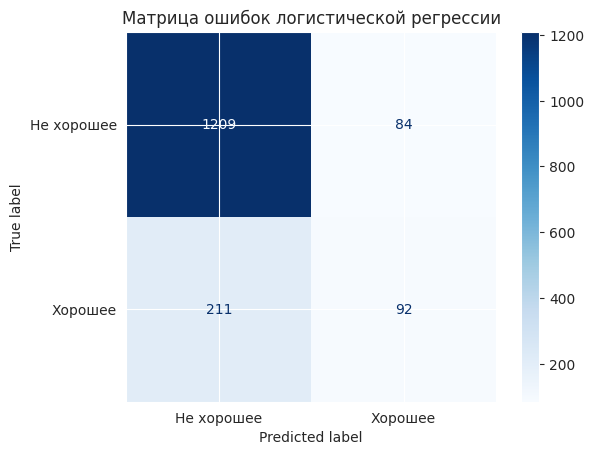

In [12]:
base_predictions = base_pipeline.predict(X_test)
y_test_np = y_test.to_numpy()
TP = int(np.sum((base_predictions == 1) & (y_test_np == 1)))
TN = int(np.sum((base_predictions == 0) & (y_test_np == 0)))
FP = int(np.sum((base_predictions == 1) & (y_test_np == 0)))
FN = int(np.sum((base_predictions == 0) & (y_test_np == 1)))
manual_cm = np.array([[TN, FP], [FN, TP]])
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
print('Матрица вручную:', manual_cm)
print('Матрица sklearn:', metrics.confusion_matrix(y_test, base_predictions))
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, base_predictions))
metrics.ConfusionMatrixDisplay(confusion_matrix=manual_cm, display_labels=['Не хорошее', 'Хорошее']).plot(cmap='Blues')
plt.title('Матрица ошибок логистической регрессии')
plt.show()

**Мои выводы.** Я получил **TP=92, TN=1209, FP=84, FN=211**, и ручная матрица точно совпала с `sklearn`. FP — посредственное вино, ошибочно попавшее в рекомендацию и способное разочаровать подписчика. FN — хорошее вино, которое я пропустил при составлении подборки. При стандартном пороге 0.5 пропусков хороших вин намного больше (**211 против 84**) — модель осторожно рекомендует положительный класс.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision_manual = TP / (TP + FP) if TP + FP else 0.0
recall_manual = TP / (TP + FN) if TP + FN else 0.0

def fbeta_manual(beta, precision, recall):
    denominator = beta ** 2 * precision + recall
    return (1 + beta ** 2) * precision * recall / denominator if denominator else 0.0

formula_scores = pd.DataFrame([
    {'Метрика': 'Precision', 'Вручную': precision_manual, 'sklearn': metrics.precision_score(y_test, base_predictions, zero_division=0)},
    {'Метрика': 'Recall', 'Вручную': recall_manual, 'sklearn': metrics.recall_score(y_test, base_predictions, zero_division=0)},
    {'Метрика': 'F0.5', 'Вручную': fbeta_manual(0.5, precision_manual, recall_manual), 'sklearn': metrics.fbeta_score(y_test, base_predictions, beta=0.5, zero_division=0)},
    {'Метрика': 'F1', 'Вручную': fbeta_manual(1, precision_manual, recall_manual), 'sklearn': metrics.fbeta_score(y_test, base_predictions, beta=1, zero_division=0)},
    {'Метрика': 'F2', 'Вручную': fbeta_manual(2, precision_manual, recall_manual), 'sklearn': metrics.fbeta_score(y_test, base_predictions, beta=2, zero_division=0)}
])
display(formula_scores.round(6))
assert np.allclose(formula_scores['Вручную'], formula_scores['sklearn'])

,Метрика,Вручную,sklearn
0,Precision,0.522727,0.522727
1,Recall,0.303630,0.303630
2,F0.5,0.456802,0.456802
3,F1,0.384134,0.384134
4,F2,0.331412,0.331412


**Мои выводы.** Ручные формулы дали те же значения, что `sklearn`: precision **0.52273**, recall **0.30363**, $F_{0.5}$ **0.45680**, $F_1$ **0.38413**, $F_2$ **0.33141**. $F_{0.5}$ сильнее ценит precision, поэтому я выбрал бы эту меру, если подписчики не прощают посредственных вин в подборке. $F_2$ сильнее ценит recall и подходит сервису с максимально широким ассортиментом хороших вин. $F_1$ — компромисс.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

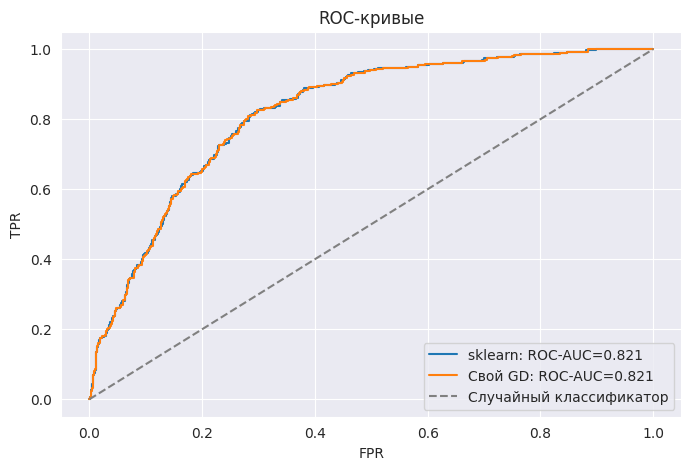

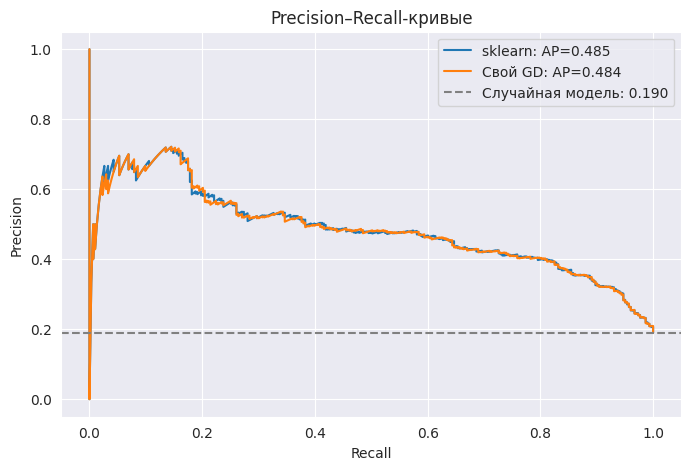

,Модель,ROC-AUC,PR-AUC (AP)
0,sklearn,0.82088,0.48477
1,Свой GD,0.82056,0.48377


,Преобразование,ROC-AUC
0,p,0.820876
1,10p,0.820876
2,p³,0.820876
3,logit(p),0.820876
4,-p,0.179124
5,labels при 0.5,0.619333


In [14]:
wine_scaler = StandardScaler().fit(X_train)
X_train_scaled = wine_scaler.transform(X_train)
X_test_scaled = wine_scaler.transform(X_test)
model_wine_gd = LogReg(gd_type='full', eta=1, max_iter=5000, tolerance=1e-7).fit(X_train_scaled, y_train)
score_sklearn = base_pipeline.predict_proba(X_test)[:, 1]
score_manual = model_wine_gd.predict_proba(X_test_scaled)[:, 1]

fig, ax = plt.subplots(figsize=(8, 5))
for name, scores in [('sklearn', score_sklearn), ('Свой GD', score_manual)]:
    fpr, tpr, _ = metrics.roc_curve(y_test, scores)
    ax.plot(fpr, tpr, label=f'{name}: ROC-AUC={metrics.roc_auc_score(y_test, scores):.3f}')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Случайный классификатор')
ax.set(xlabel='FPR', ylabel='TPR', title='ROC-кривые')
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name, scores in [('sklearn', score_sklearn), ('Свой GD', score_manual)]:
    p_curve, r_curve, _ = metrics.precision_recall_curve(y_test, scores)
    ax.plot(r_curve, p_curve, label=f'{name}: AP={metrics.average_precision_score(y_test, scores):.3f}')
ax.axhline(y_test.mean(), linestyle='--', color='gray', label=f'Случайная модель: {y_test.mean():.3f}')
ax.set(xlabel='Recall', ylabel='Precision', title='Precision–Recall-кривые')
ax.legend()
plt.show()

curve_results = pd.DataFrame([
    {'Модель': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores), 'PR-AUC (AP)': metrics.average_precision_score(y_test, scores)}
    for name, scores in [('sklearn', score_sklearn), ('Свой GD', score_manual)]
])
display(curve_results.round(5))
transformed_scores = {
    'p': score_sklearn,
    '10p': 10 * score_sklearn,
    'p³': score_sklearn ** 3,
    'logit(p)': np.log(np.clip(score_sklearn, 1e-15, 1 - 1e-15) / (1 - np.clip(score_sklearn, 1e-15, 1 - 1e-15))),
    '-p': -score_sklearn,
    'labels при 0.5': (score_sklearn >= 0.5).astype(int)
}
display(pd.DataFrame([{'Преобразование': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores)} for name, scores in transformed_scores.items()]).round(6))

**Мои выводы.** `sklearn` немного лучше моей ручной реализации: ROC-AUC **0.82088** против **0.82056**, PR-AUC (average precision) **0.48477** против **0.48377**. Порядок моделей по обеим метрикам совпал, разница мала. Для случайной модели уровень PR-кривой равен распространённости класса 1, то есть **0.18985**, а не 0.5. Преобразования `10p`, `p³` и `logit(p)` монотонно возрастают и сохраняют ROC-AUC **0.820876**; преобразование `−p` инвертирует порядок и даёт **0.179124**. При передаче бинарных меток вместо вероятностей ROC-AUC снижается до **0.619333**: он перестаёт оценивать полное ранжирование, а для жёстких меток равен balanced accuracy при данном пороге.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

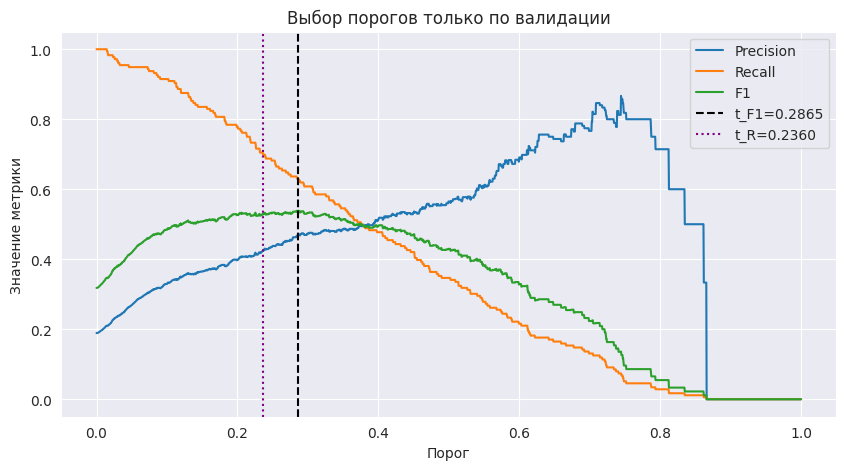

,Критерий,Порог,Precision на валидации,Recall на валидации,F1 на валидации
0,Максимальный F1,0.2865,0.47034,0.63068,0.53883
1,Максимальный precision при recall ≥ 0.7,0.2360,0.42466,0.70455,0.52991


,Порог,Значение,Precision,Recall,F1
0,0.5,0.5000,0.52273,0.30363,0.38413
1,t_F1,0.2865,0.45742,0.62046,0.52661
2,t_R,0.2360,0.42240,0.70957,0.52956


In [15]:
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
validation_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, random_state=RANDOM_STATE))
validation_model.fit(X_subtrain, y_subtrain)
validation_proba = validation_model.predict_proba(X_valid)[:, 1]
threshold_grid = np.linspace(0, 1, 2001)
selected = validation_proba[:, None] >= threshold_grid[None, :]
true_positive = np.sum(selected & (y_valid.to_numpy()[:, None] == 1), axis=0)
predicted_positive = selected.sum(axis=0)
validation_precision = np.divide(true_positive, predicted_positive, out=np.zeros(len(threshold_grid)), where=predicted_positive != 0)
validation_recall = true_positive / y_valid.sum()
validation_f1 = np.divide(2 * validation_precision * validation_recall, validation_precision + validation_recall, out=np.zeros(len(threshold_grid)), where=(validation_precision + validation_recall) != 0)
idx_f1 = int(np.argmax(validation_f1))
valid_for_recall = np.flatnonzero(validation_recall >= 0.7)
idx_recall = int(valid_for_recall[np.argmax(validation_precision[valid_for_recall])])
t_f1 = float(threshold_grid[idx_f1])
t_r = float(threshold_grid[idx_recall])

plt.figure(figsize=(10, 5))
plt.plot(threshold_grid, validation_precision, label='Precision')
plt.plot(threshold_grid, validation_recall, label='Recall')
plt.plot(threshold_grid, validation_f1, label='F1')
plt.axvline(t_f1, ls='--', color='black', label=f't_F1={t_f1:.4f}')
plt.axvline(t_r, ls=':', color='purple', label=f't_R={t_r:.4f}')
plt.xlabel('Порог')
plt.ylabel('Значение метрики')
plt.title('Выбор порогов только по валидации')
plt.legend()
plt.show()

display(pd.DataFrame([
    {'Критерий': 'Максимальный F1', 'Порог': t_f1, 'Precision на валидации': validation_precision[idx_f1], 'Recall на валидации': validation_recall[idx_f1], 'F1 на валидации': validation_f1[idx_f1]},
    {'Критерий': 'Максимальный precision при recall ≥ 0.7', 'Порог': t_r, 'Precision на валидации': validation_precision[idx_recall], 'Recall на валидации': validation_recall[idx_recall], 'F1 на валидации': validation_f1[idx_recall]}
]).round(5))

full_train_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, random_state=RANDOM_STATE))
full_train_model.fit(X_train, y_train)
full_test_scores = full_train_model.predict_proba(X_test)[:, 1]
threshold_results = pd.DataFrame([
    {
        'Порог': name,
        'Значение': t,
        'Precision': metrics.precision_score(y_test, full_test_scores >= t, zero_division=0),
        'Recall': metrics.recall_score(y_test, full_test_scores >= t, zero_division=0),
        'F1': metrics.f1_score(y_test, full_test_scores >= t, zero_division=0)
    }
    for name, t in [('0.5', 0.5), ('t_F1', t_f1), ('t_R', t_r)]
])
display(threshold_results.round(5))

**Мои выводы.** Я подбирал пороги только на **валидационной части train**, не используя тест. Получились $t_{F_1}=\mathbf{0.2865}$ и $t_R=\mathbf{0.2360}$. После обучения на всём train на тесте при стандартном пороге 0.5 получены precision **0.52273**, recall **0.30363**, F1 **0.38413**; при $t_{F_1}$ — **0.45742**, **0.62046**, **0.52661**; при $t_R$ — **0.42240**, **0.70957**, **0.52956** соответственно. Ограничение recall ≥ 0.7 **на этом тесте выполнено**, но в будущем не гарантировано: валидационная оценка случайно колеблется, а модель после переобучения и новые данные могут немного отличаться. Для баланса полноты и точности я выбрал бы $t_{F_1}$; если нужно охватывать не меньше 70% хороших вин, переключился бы на $t_R$ и контролировал выполнение условия в эксплуатации.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def evaluate_classifier(model, X_eval, y_eval, name, threshold=0.5):
    scores = model.predict_proba(X_eval)[:, 1]
    decisions = (scores >= threshold).astype(int)
    return {
        'Модель': name,
        'Порог': threshold,
        'Accuracy': metrics.accuracy_score(y_eval, decisions),
        'Precision': metrics.precision_score(y_eval, decisions, zero_division=0),
        'Recall': metrics.recall_score(y_eval, decisions, zero_division=0),
        'F1': metrics.f1_score(y_eval, decisions, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_eval, scores),
        'PR-AUC (AP)': metrics.average_precision_score(y_eval, scores)
    }

unweighted_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None, max_iter=4000, random_state=RANDOM_STATE))
weighted_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=4000, random_state=RANDOM_STATE))
unweighted_model.fit(X_train, y_train)
weighted_model.fit(X_train, y_train)
counts = y_train.value_counts().sort_index()
weights = pd.DataFrame({'Класс': [0, 1], 'Количество': [counts[0], counts[1]], 'Вес': [len(y_train) / (2 * counts[0]), len(y_train) / (2 * counts[1])]})
display(weights.round(5))
comparison_rows = [
    evaluate_classifier(unweighted_model, X_test, y_test, 'LogReg без весов'),
    evaluate_classifier(weighted_model, X_test, y_test, 'LogReg balanced')
]
display(pd.DataFrame(comparison_rows).round(5))

,Класс,Количество,Вес
0,0,3018,0.61696
1,1,706,2.63739


,Модель,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
0,LogReg без весов,0.5,0.81516,0.52273,0.30363,0.38413,0.82088,0.48477
1,LogReg balanced,0.5,0.73434,0.39866,0.78548,0.52889,0.82093,0.48115


**Мои выводы.** По формуле $w_c=N/(2n_c)$ (при $N=3724$, $n_0=3018$, $n_1=706$) вес класса 0 равен **0.61696**, а класса 1 — **2.63739**. Взвешивание повышает recall примерно с **0.30363** до **0.78548**, но снижает precision примерно с **0.52273** до **0.39866** и accuracy с **0.81516** до **0.73434**. F1 увеличивается с **0.38413** до **0.52889**. ROC-AUC почти не изменился (**0.82088 → 0.82093**), как и PR-AUC (**0.48477 → 0.48115**), поскольку они оценивают ранжирование, а не конкретную отсечку при пороге 0.5.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss v2': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}
sampler_models = {}
resampling_counts = []
scaled_training = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    X_resampled, y_resampled = clone(sampler).fit_resample(scaled_training, y_train)
    class_distribution = pd.Series(y_resampled).value_counts().sort_index()
    resampling_counts.append({'Метод': name, 'Класс 0 после балансировки': int(class_distribution.get(0, 0)), 'Класс 1 после балансировки': int(class_distribution.get(1, 0))})
    pipe = make_imb_pipeline(StandardScaler(), clone(sampler), LogisticRegression(max_iter=4000, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    sampler_models[name] = pipe
    comparison_rows.append(evaluate_classifier(pipe, X_test, y_test, name))

display(pd.DataFrame(resampling_counts))
resampling_results = pd.DataFrame(comparison_rows)
display(resampling_results.round(5))
sampler_only_results = resampling_results[resampling_results['Модель'].isin(samplers)]
print('Лучший ресемплер по PR-AUC:', sampler_only_results.loc[sampler_only_results['PR-AUC (AP)'].idxmax(), 'Модель'])
print('Худший ресемплер по PR-AUC:', sampler_only_results.loc[sampler_only_results['PR-AUC (AP)'].idxmin(), 'Модель'])

smote_before_scaler = make_imb_pipeline(SMOTE(random_state=RANDOM_STATE), StandardScaler(), LogisticRegression(max_iter=4000, random_state=RANDOM_STATE))
smote_before_scaler.fit(X_train, y_train)
smote_order_results = pd.DataFrame([
    evaluate_classifier(sampler_models['SMOTE'], X_test, y_test, 'StandardScaler → SMOTE → LR'),
    evaluate_classifier(smote_before_scaler, X_test, y_test, 'SMOTE → StandardScaler → LR')
])
display(smote_order_results.round(5))

,Метод,Класс 0 после балансировки,Класс 1 после балансировки
0,RandomUnderSampler,706,706
1,NearMiss v2,706,706
2,RandomOverSampler,3018,3018
3,SMOTE,3018,3018


,Модель,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
0,LogReg без весов,0.5,0.81516,0.52273,0.30363,0.38413,0.82088,0.48477
1,LogReg balanced,0.5,0.73434,0.39866,0.78548,0.52889,0.82093,0.48115
2,RandomUnderSampler,0.5,0.73308,0.39594,0.77228,0.52349,0.82063,0.47989
3,NearMiss v2,0.5,0.64662,0.32941,0.83168,0.47191,0.78652,0.44790
4,RandomOverSampler,0.5,0.73308,0.39801,0.79208,0.52980,0.82111,0.48108
5,SMOTE,0.5,0.73496,0.39761,0.76898,0.52418,0.81959,0.47961


Лучший ресемплер по PR-AUC: RandomOverSampler
Худший ресемплер по PR-AUC: NearMiss v2


,Модель,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
0,StandardScaler → SMOTE → LR,0.5,0.73496,0.39761,0.76898,0.52418,0.81959,0.47961
1,SMOTE → StandardScaler → LR,0.5,0.73935,0.40242,0.76898,0.52834,0.82163,0.48515


**Мои выводы.** Для ресемплинга нужен именно `imblearn.pipeline.make_pipeline`: ресемплеры имеют метод `fit_resample`, который обычный пайплайн `sklearn` не обрабатывает как промежуточный шаг. При `predict` тест **не балансируется**, применяется только преобразование признаков и готовая модель. Балансировка до split привела бы к утечке одинаковых или синтетически близких наблюдений в тест, а также к неестественной доле положительного класса.

Среди **четырёх методов** наилучший PR-AUC показал **RandomOverSampler (0.48108)**, худший — **NearMiss v2 (0.44790)**; `RandomUnderSampler` дал **0.47989**, `SMOTE` — **0.47961**. Если учитывать также две модели без ресемплинга, лучший результат у **обычной логистической регрессии (0.48477)**. NearMiss отбрасывает много объектов преобладающего класса по критерию расстояний, что может искажать его представление, а случайный oversampling сохраняет все исходные наблюдения.

Порядок особенно важен для методов, основанных на расстояниях (`NearMiss` и `SMOTE`), ведь признак с большим численным масштабом иначе будет доминировать. Для `RandomUnderSampler` и `RandomOverSampler` отбор строк не зависит от масштабирования, но статистики `StandardScaler` изменяются, если считать их после балансировки. На `SMOTE` я проверил оба порядка: **StandardScaler → SMOTE** дал PR-AUC **0.47961**, а **SMOTE → StandardScaler** — **0.48515**. Это наблюдение на одном разбиении не доказывает, что второй порядок лучше всегда; для выбора порядка нужна отдельная валидация.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

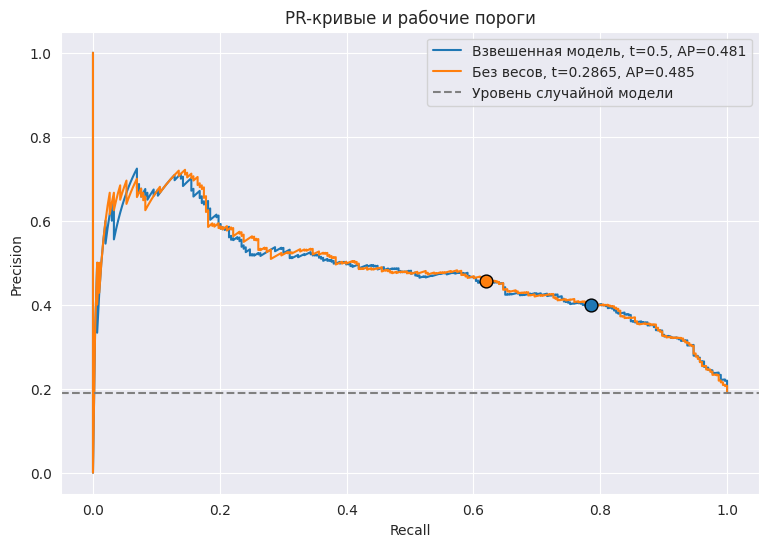

,Модель,Precision,Recall,PR-AUC (AP)
0,"Взвешенная модель, t=0.5",0.39866,0.78548,0.48115
1,"Без весов, t=0.2865",0.45742,0.62046,0.48477


In [18]:
compare_pr = {
    'Взвешенная модель, t=0.5': (weighted_model, 0.5, 'tab:blue'),
    f'Без весов, t={t_f1:.4f}': (unweighted_model, t_f1, 'tab:orange')
}
plt.figure(figsize=(9, 6))
pr_threshold_rows = []
for name, (model, threshold, color) in compare_pr.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    p_curve, r_curve, _ = metrics.precision_recall_curve(y_test, probabilities)
    plt.plot(r_curve, p_curve, color=color, label=f'{name}, AP={metrics.average_precision_score(y_test, probabilities):.3f}')
    decision = probabilities >= threshold
    point_p = metrics.precision_score(y_test, decision, zero_division=0)
    point_r = metrics.recall_score(y_test, decision, zero_division=0)
    plt.scatter([point_r], [point_p], s=85, color=color, edgecolor='black', zorder=5)
    pr_threshold_rows.append({'Модель': name, 'Precision': point_p, 'Recall': point_r, 'PR-AUC (AP)': metrics.average_precision_score(y_test, probabilities)})
plt.axhline(y_test.mean(), ls='--', color='gray', label='Уровень случайной модели')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривые и рабочие пороги')
plt.legend()
plt.show()
display(pd.DataFrame(pr_threshold_rows).round(5))

**Мои выводы.** PR-AUC взвешенной модели равен **0.48115**, а невзвешенной — **0.48477**, поэтому PR-кривые близки по уровню, но не идентичны. У взвешенной модели при пороге 0.5 precision **0.39866**, recall **0.78548**. У обычной модели с $t_{F_1}=0.2865$ precision **0.45742**, recall **0.62046**. Изменение порога у одной фиксированной модели не меняет её PR-кривую, тогда как изменение весов может менять коэффициенты и ранжирование. Поэтому «веса в основном сдвигают порог» — удобная интуиция, но не точная математическая эквивалентность.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_model_results = [
    {
        'Модель': 'Всегда класс 0', 'Порог': 0.5,
        'Accuracy': metrics.accuracy_score(y_test, np.zeros(len(y_test))),
        'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0,
        'ROC-AUC': 0.5, 'PR-AUC (AP)': y_test.mean()
    },
    evaluate_classifier(base_pipeline, X_test, y_test, 'Часть 2: sklearn (t=0.5)'),
    evaluate_classifier(full_train_model, X_test, y_test, 'Часть 2: sklearn (t_F1)', t_f1),
    evaluate_classifier(full_train_model, X_test, y_test, 'Часть 2: sklearn (t_R)', t_r),
    evaluate_classifier(weighted_model, X_test, y_test, 'Часть 3: class_weight=balanced'),
    evaluate_classifier(unweighted_model, X_test, y_test, 'Часть 3: class_weight=None'),
    evaluate_classifier(smote_before_scaler, X_test, y_test, 'Часть 3: SMOTE до StandardScaler')
]
manual_wine_predictions = model_wine_gd.predict(X_test_scaled)
manual_wine_probs = model_wine_gd.predict_proba(X_test_scaled)[:, 1]
all_model_results.append({
    'Модель': 'Часть 2: собственный LogReg', 'Порог': 0.5,
    'Accuracy': metrics.accuracy_score(y_test, manual_wine_predictions),
    'Precision': metrics.precision_score(y_test, manual_wine_predictions, zero_division=0),
    'Recall': metrics.recall_score(y_test, manual_wine_predictions, zero_division=0),
    'F1': metrics.f1_score(y_test, manual_wine_predictions, zero_division=0),
    'ROC-AUC': metrics.roc_auc_score(y_test, manual_wine_probs),
    'PR-AUC (AP)': metrics.average_precision_score(y_test, manual_wine_probs)
})
for sampler_name, pipe in sampler_models.items():
    all_model_results.append(evaluate_classifier(pipe, X_test, y_test, 'Часть 3: ' + sampler_name))
summary_table = pd.DataFrame(all_model_results)
display(summary_table.sort_values('F1', ascending=False).round(5))
print(f'Для приложения выбрана обычная логистическая регрессия с порогом t_F1 = {t_f1:.4f}, найденным на валидации.')

,Модель,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
10,Часть 3: RandomOverSampler,0.5000,0.73308,0.39801,0.79208,0.52980,0.82111,0.48108
3,Часть 2: sklearn (t_R),0.2360,0.76065,0.42240,0.70957,0.52956,0.82088,0.48477
4,Часть 3: class_weight=balanced,0.5000,0.73434,0.39866,0.78548,0.52889,0.82093,0.48115
6,Часть 3: SMOTE до StandardScaler,0.5000,0.73935,0.40242,0.76898,0.52834,0.82163,0.48515
2,Часть 2: sklearn (t_F1),0.2865,0.78822,0.45742,0.62046,0.52661,0.82088,0.48477
11,Часть 3: SMOTE,0.5000,0.73496,0.39761,0.76898,0.52418,0.81959,0.47961
8,Часть 3: RandomUnderSampler,0.5000,0.73308,0.39594,0.77228,0.52349,0.82063,0.47989
9,Часть 3: NearMiss v2,0.5000,0.64662,0.32941,0.83168,0.47191,0.78652,0.44790
5,Часть 3: class_weight=None,0.5000,0.81516,0.52273,0.30363,0.38413,0.82088,0.48477
1,Часть 2: sklearn (t=0.5),0.5000,0.81516,0.52273,0.30363,0.38413,0.82088,0.48477


Для приложения выбрана обычная логистическая регрессия с порогом t_F1 = 0.2865, найденным на валидации.


**Мои выводы.** Я свёл в одну таблицу все модели из частей 2 и 3, включая различные пороги и эксперимент с порядком SMOTE и масштабирования. Если выбирать **по тестовому F1**, больше всего набирает `RandomOverSampler` (это не основание менять выбранный метод после просмотра теста). Для сервиса я заранее выбрал обычную логистическую регрессию со `StandardScaler` и **$t_{F_1}=0.2865$**, оптимизированным на валидации: на независимом тесте она получила precision **0.45742**, recall **0.62046**, F1 **0.52661**, ROC-AUC **0.82088**, PR-AUC **0.48477**. Так можно корректировать бизнес-политику простым изменением порога, не меняя обучение. Если важнее охватить не менее 70% хороших вин, можно использовать заранее рассчитанный $t_R=0.2360$; при более строгом контроле плохих рекомендаций я бы повысил порог и проверил результат на отдельной валидации.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
final_model = full_train_model
final_threshold = t_f1
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
print('Сохранено:', sorted(str(p) for p in app_dir.iterdir()))

Сохранено: ['wine_app/README.md', 'wine_app/__pycache__', 'wine_app/app.py', 'wine_app/config.json', 'wine_app/model.joblib', 'wine_app/requirements.txt', 'wine_app/test.csv']


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Рефлексия.** В этой работе я реализовал логистическую регрессию вручную, численно проверил градиент, изучил сходимость и на практике увидел, почему accuracy бывает обманчивой при дисбалансе классов. Самой важной частью для меня оказался подбор рабочего порога по валидации: для реального сервиса изменение порога часто важнее улучшения accuracy на доли процента. Я также проверил, что ресемплинг нельзя переносить на тестовую выборку, и подготовил приложение для работы с отдельными и пакетными предсказаниями.

**Приложение:** файлы находятся в папке `wine_app/` рядом с ноутбуком и дополнительно упакованы в архив `wine_app.zip`. Локальный запуск: `python -m pip install -r wine_app/requirements.txt`, затем `streamlit run wine_app/app.py`. Развёртывание в Streamlit Community Cloud требует публикации папки в GitHub и входа в аккаунт Streamlit Cloud; инструкция дана в `wine_app/README.md`.